# 📧 Email / SMS Spam Detection with Machine Learning and NLP

## Objective
Build and compare binary text classifiers that label a message as **spam** or **ham** (legitimate), using the **SMS Spam Collection** dataset.

**Workflow**
1. Load the dataset and *inspect* its structure (no assumed column layout)
2. Explore the data and class balance
3. Clean the text (lowercase, punctuation, stopwords) while keeping useful spam signals
4. Convert text to numbers with **TF-IDF**, inside a scikit-learn `Pipeline` to prevent data leakage
5. Train **Multinomial Naive Bayes** and **Logistic Regression** on an 80/20 stratified split
6. Evaluate with accuracy, precision, recall, F1, classification reports and confusion matrices
7. Choose the best model from the *actual* results, then predict on new messages

> **Terminology:** *ham* = legitimate message, *spam* = unwanted message. The SMS dataset is used here because it is the standard public benchmark; the same approach applies to e-mail text.

## 1. Library Imports
Only `wordcloud` and `nltk` are optional. If they are missing, the notebook still runs (see the fallbacks below).

In [1]:
import os
import re
import sys
import string
import zipfile
import warnings
import subprocess
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 100)

RANDOM_STATE = 42   # one seed used everywhere, so results are reproducible
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset Loading

### How to get the data
| Source | Link | File you get |
|---|---|---|
| **UCI Repository** (original) | https://archive.ics.uci.edu/dataset/228/sms+spam+collection | `SMSSpamCollection` (tab-separated, **no header**: `label<TAB>message`) |
| **Kaggle** | https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset | `spam.csv` (comma-separated, **latin-1** encoding, columns `v1`, `v2` plus empty `Unnamed:` columns) |

### How this notebook finds the file
1. If you set `DATA_PATH` below, that file is used.
2. Otherwise the notebook looks for common file names in the current folder (and `data/`).
3. If nothing is found, it tries to download the UCI zip automatically (needs internet).
4. If that fails, download the file manually and place it next to this notebook (or set `DATA_PATH`).

The two formats differ, so the code **reads the file, then detects which column is the label and which is the message** from the content itself instead of assuming names or positions.

In [2]:
# ---- Optional: set this to the full path of your dataset file, e.g. "data/spam.csv"
DATA_PATH = None

CANDIDATE_PATHS = [
    "SMSSpamCollection", "SMSSpamCollection.txt", "spam.csv", "sms_spam.csv",
    "data/SMSSpamCollection", "data/SMSSpamCollection.txt", "data/spam.csv",
    "SMS_Spam_Collection/SMSSpamCollection",
]
UCI_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"


def find_dataset():
    """Return the first existing dataset path, or None."""
    if DATA_PATH and os.path.exists(DATA_PATH):
        return DATA_PATH
    for p in CANDIDATE_PATHS:
        if os.path.exists(p):
            return p
    return None


def try_download_uci(folder="data"):
    """Try to download and unzip the dataset from UCI. Returns the file path or None."""
    try:
        os.makedirs(folder, exist_ok=True)
        zip_path = os.path.join(folder, "sms_spam_collection.zip")
        with urllib.request.urlopen(UCI_URL, timeout=30) as resp, open(zip_path, "wb") as f:
            f.write(resp.read())
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(folder)
        extracted = os.path.join(folder, "SMSSpamCollection")
        return extracted if os.path.exists(extracted) else None
    except Exception as err:
        print(f"Automatic download failed ({type(err).__name__}: {err}).")
        return None


dataset_path = find_dataset() or try_download_uci()
if dataset_path is None:
    raise FileNotFoundError(
        "Dataset not found. Download it from UCI or Kaggle (links above), place it next to "
        "this notebook, or set DATA_PATH to its location, then re-run this cell."
    )
print("Using dataset file:", dataset_path)

Using dataset file: data\SMSSpamCollection


In [3]:
def read_raw(path):
    """Read either the UCI tab-separated file (no header) or a Kaggle-style CSV."""
    if path.lower().endswith(".csv"):
        try:
            return pd.read_csv(path, encoding="utf-8")
        except UnicodeDecodeError:
            return pd.read_csv(path, encoding="latin-1")      # Kaggle spam.csv needs this
    # UCI file: tab separated, no header; quoting=3 (QUOTE_NONE) because messages contain quote marks
    return pd.read_csv(path, sep="\t", header=None, names=["label", "message"],
                       encoding="latin-1", quoting=3)


raw = read_raw(dataset_path)
raw = raw.dropna(axis=1, how="all")        # drop columns that are completely empty
print("Raw columns found:", list(raw.columns))
raw.head()

Raw columns found: ['label', 'message']


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


### Identify the label and message columns
* **Label column** = a column whose values are only `ham` / `spam` (ignoring case and spaces).
* **Message column** = among the remaining text columns, the one with the most non-null entries. (Kaggle's `Unnamed:` columns hold only a handful of stray values, so they lose this comparison.)

In [4]:
def is_label_column(series):
    values = set(series.dropna().astype(str).str.strip().str.lower().unique())
    return len(values) > 0 and values <= {"ham", "spam"}


label_candidates = [c for c in raw.columns if is_label_column(raw[c])]
text_candidates = [c for c in raw.columns if c not in label_candidates and not pd.api.types.is_numeric_dtype(raw[c])]

assert len(label_candidates) == 1, f"Could not uniquely identify the label column: {label_candidates}"
assert len(text_candidates) >= 1, "Could not find a text column."

label_col = label_candidates[0]
text_col = max(text_candidates, key=lambda c: raw[c].notna().sum())
print(f"Label column   : '{label_col}'")
print(f"Message column : '{text_col}'")

# Standardise to two clearly named columns used for the rest of the notebook
df = raw[[label_col, text_col]].rename(columns={label_col: "label", text_col: "message"})
df["label"] = df["label"].astype(str).str.strip().str.lower()
df = df.dropna(subset=["message"])
df["message"] = df["message"].astype(str).str.strip()

Label column   : 'label'
Message column : 'message'


## 3. Data Cleaning and Exploration

In [5]:
print("Shape (rows, columns):", df.shape)
print("Column names         :", list(df.columns))
print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values per column:")
print(df.isnull().sum())

n_dupes = df.duplicated().sum()
print(f"\nExact duplicate rows (same label and message): {n_dupes}")

Shape (rows, columns): (5574, 2)
Column names         : ['label', 'message']

First 5 rows:


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"



Missing values per column:
label      0
message    0
dtype: int64

Exact duplicate rows (same label and message): 414


In [6]:
class_counts = df["label"].value_counts()
class_percent = (df["label"].value_counts(normalize=True) * 100).round(2)
class_summary = pd.DataFrame({"count": class_counts, "percentage (%)": class_percent})
print("Class distribution (before removing duplicates):")
display(class_summary)

Class distribution (before removing duplicates):


,count,percentage (%)
label,,
ham,4827,86.6
spam,747,13.4


### Class distribution visualization
The data is **imbalanced**: far more ham than spam. That is exactly why accuracy alone is misleading here (a model that always predicts "ham" would already score high accuracy but would catch **no** spam).

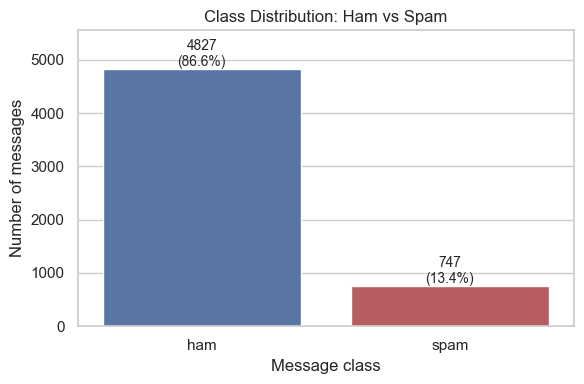

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["ham", "spam"]
sns.countplot(data=df, x="label", order=order, palette=["#4C72B0", "#C44E52"], ax=ax)
total = len(df)
for patch in ax.patches:
    count = int(patch.get_height())
    ax.annotate(f"{count}\n({count / total:.1%})", (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Class Distribution: Ham vs Spam")
ax.set_xlabel("Message class")
ax.set_ylabel("Number of messages")
ax.set_ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()

### Message length by class (quick exploratory check)
Spam messages are often longer (they pack in offers, phone numbers and calls to action).

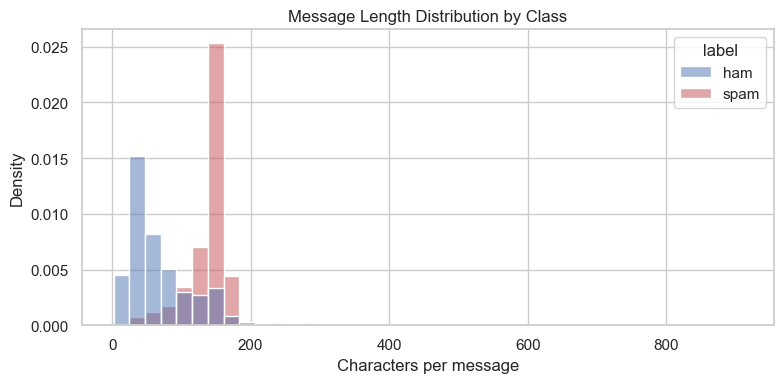

        count   mean   std   min    25%    50%    75%    max
label                                                       
ham    4827.0   71.5  58.3   2.0   33.0   52.0   93.0  910.0
spam    747.0  139.1  29.0  13.0  133.0  149.0  157.0  224.0


In [8]:
df["char_length"] = df["message"].str.len()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="char_length", hue="label", bins=40, stat="density",
             common_norm=False, palette={"ham": "#4C72B0", "spam": "#C44E52"}, ax=ax)
ax.set_title("Message Length Distribution by Class")
ax.set_xlabel("Characters per message")
plt.tight_layout()
plt.show()

print(df.groupby("label")["char_length"].describe().round(1))

### Handling duplicates
Duplicate messages are a **data-leakage risk**: if the same text lands in both the training and test sets, the test score is inflated because the model has effectively seen the answer. We therefore

1. check whether the same message appears with *conflicting* labels (and drop those ambiguous messages), and
2. keep only one copy of each remaining message.

In [9]:
labels_per_message = df.groupby("message")["label"].nunique()
conflicting_messages = labels_per_message[labels_per_message > 1].index
print(f"Messages appearing with conflicting labels: {len(conflicting_messages)}")

rows_before = len(df)
df = df[~df["message"].isin(conflicting_messages)]
df = df.drop_duplicates(subset="message").reset_index(drop=True)
print(f"Rows before: {rows_before} | after removing conflicts and duplicates: {len(df)}")

print("\nClass distribution after de-duplication:")
display(pd.DataFrame({"count": df["label"].value_counts(),
                      "percentage (%)": (df["label"].value_counts(normalize=True) * 100).round(2)}))

Messages appearing with conflicting labels: 0
Rows before: 5574 | after removing conflicts and duplicates: 5160

Class distribution after de-duplication:


,count,percentage (%)
label,,
ham,4518,87.56
spam,642,12.44


### Encode the labels consistently
We fix one mapping and use it everywhere: **`ham = 0`, `spam = 1`**. Spam is the *positive class*, so precision, recall and F1 are all reported *for spam*.

In [10]:
LABEL_MAP = {"ham": 0, "spam": 1}
CLASS_NAMES = ["ham", "spam"]            # index 0 -> ham, index 1 -> spam

df["label_num"] = df["label"].map(LABEL_MAP)
assert df["label_num"].notna().all(), "Unexpected label value found."
df["label_num"] = df["label_num"].astype(int)
df[["label", "label_num"]].drop_duplicates().sort_values("label_num")

,label,label_num
0,ham,0
2,spam,1


## 4. Text Preprocessing

Steps applied to every message (in this order):

| Step | Why |
|---|---|
| **Lowercase** | `FREE`, `Free` and `free` become the same token |
| **Mark currency symbols** (`£ $ €` → `currencysymbol`) | Money symbols are strong spam signals, and they would be lost when punctuation is removed |
| **Remove punctuation** | Reduces noise (`free!!!` → `free`) |
| **Remove stopwords** | Drops very common words (`the`, `is`, `to`) that carry little class information |
| **Optional stemming** (off by default) | Reduces words to a root (`winning` → `win`); can help a little but makes tokens harder to read |

**What we deliberately keep**
* **Digits are kept**: phone numbers, short codes and prize amounts (`80062`, `2000`) are useful spam indicators.
* **Slang is kept** (`u`, `ur`, `txt`): it is not in standard stopword lists, and its pattern differs between spam and ham.

**Is cleaning before the split a leakage problem?** No. This function treats each message independently and learns nothing from the data (no vocabulary, no statistics). The steps that *do* learn from data (the TF-IDF vocabulary and IDF weights) are placed inside the Pipeline and are fitted on training data only.

In [11]:
# ---- Stopword list: NLTK if available, otherwise scikit-learn's built-in English list
try:
    import nltk
    try:
        nltk.data.find("corpora/stopwords")
    except LookupError:
        nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords
    STOPWORDS = set(stopwords.words("english"))
    print(f"Using NLTK stopwords ({len(STOPWORDS)} words).")
except Exception as err:
    STOPWORDS = set(ENGLISH_STOP_WORDS)
    print(f"NLTK stopwords unavailable ({type(err).__name__}); using scikit-learn's list "
          f"({len(STOPWORDS)} words).")

# ---- Optional stemming (Porter stemmer needs no extra data download)
USE_STEMMING = False
if USE_STEMMING:
    from nltk.stem import PorterStemmer
    stemmer = PorterStemmer()

PUNCT_TABLE = str.maketrans("", "", string.punctuation)   # deletes every punctuation character


def clean_text(text):
    """Lowercase -> mark currency symbols -> strip punctuation -> remove stopwords (-> optional stemming)."""
    text = str(text).lower()
    text = re.sub(r"[£$€]", " currencysymbol ", text)       # keep the 'money' signal
    text = text.translate(PUNCT_TABLE)                       # remove punctuation, keep digits
    tokens = [t for t in text.split() if t not in STOPWORDS]
    if USE_STEMMING:
        tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)


df["clean_message"] = df["message"].apply(clean_text)

print("Messages that became empty after cleaning:", (df["clean_message"].str.strip() == "").sum())
print("\nBefore vs after cleaning:")
display(df[["message", "clean_message"]].sample(5, random_state=RANDOM_STATE))

NLTK stopwords unavailable (ModuleNotFoundError); using scikit-learn's list (318 words).
Messages that became empty after cleaning: 13

Before vs after cleaning:


,message,clean_message
2387,they released another Italian one today and it has a cosign option,released italian today cosign option
3525,I'm not. She lip synced with shangela.,im lip synced shangela
654,Carlos'll be here in a minute if you still need to buy,carlosll minute need buy
1084,Ok ill tell the company,ok ill tell company
2516,"That's what I love to hear :V see you sundayish, then",thats love hear v sundayish


## 5. TF-IDF Explanation and Feature Extraction

### What is TF-IDF?
**TF-IDF** (*Term Frequency – Inverse Document Frequency*) turns text into numbers by scoring how important each word is to a message *relative to all messages*.

* **Term Frequency (TF)**: how often a word appears in this message.
* **Inverse Document Frequency (IDF)**: how *rare* the word is across all messages. Words in almost every message get a low weight; rare, distinctive words get a high weight.

$$\text{TF-IDF}(t, d) = \text{TF}(t, d) \times \text{IDF}(t), \qquad \text{IDF}(t) = \ln\!\frac{1 + N}{1 + \text{df}(t)} + 1$$

(this is scikit-learn's smoothed version; $N$ = number of messages, $\text{df}(t)$ = number of messages containing $t$). Each message vector is then length-normalised.

### Why it works well for spam detection
* Distinctive words such as *"winner"*, *"prize"* or *"claim"* get high weights, while filler words get low weights.
* A simple *bag-of-words* count would let long messages dominate. TF-IDF with normalisation avoids this.
* It produces **sparse** vectors that linear models and Naive Bayes handle quickly.

### Settings used
| Parameter | Value | Reason |
|---|---|---|
| `ngram_range` | `(1, 2)` | Single words **and** two-word phrases (e.g. *"call now"*, *"free entry"*) |
| `min_df` | `2` | Ignore words/phrases seen in only one message (mostly typos or noise) |
| `sublinear_tf` | `True` | Uses `1 + log(tf)` so repeated words do not dominate |

### Avoiding data leakage
`TfidfVectorizer.fit` learns the vocabulary and IDF values. If it were fitted on the *whole* dataset, information from the test messages would leak into training. Putting it **inside a `Pipeline`** means that it is fitted **only on training data** when `pipeline.fit(X_train, y_train)` is called, and merely *applied* to test data afterwards. The same applies to every fold during cross-validation.

## 6. Train/Test Split
80% training / 20% testing, `random_state=42`, and `stratify=y` so that both parts keep the same spam/ham proportion.

In [12]:
X = df["clean_message"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]} messages | Test set: {X_test.shape[0]} messages")
split_check = pd.DataFrame({
    "train (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "test (%)": (y_test.value_counts(normalize=True) * 100).round(2),
}).rename(index={0: "ham", 1: "spam"})
print("\nClass proportions are preserved by stratification:")
display(split_check)

Training set: 4128 messages | Test set: 1032 messages

Class proportions are preserved by stratification:


,train (%),test (%)
label_num,,
ham,87.55,87.6
spam,12.45,12.4


## 7. Model Training

Two models, each wrapped in a pipeline `TF-IDF → classifier`:

1. **Multinomial Naive Bayes**: a fast probabilistic baseline that suits word-count/TF-IDF features. `alpha=0.1` is a mild smoothing value chosen up front (the default `1.0` is also reasonable); it was **not** tuned on the test set.
2. **Logistic Regression**: a linear model that learns a weight per word, which also makes it interpretable. `class_weight="balanced"` gives the rarer spam class more weight so the model does not simply favour ham.

Before the final fit, we run **5-fold stratified cross-validation on the training set only** as a sanity check. The test set stays untouched until the evaluation section.

In [13]:
def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)


models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", make_tfidf()),
        ("clf", MultinomialNB(alpha=0.1)),
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", make_tfidf()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
}

# --- Cross-validation on the TRAINING data only (the vectorizer is re-fitted inside each fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    cv_rows.append({"Model": name, "CV F1 (spam) mean": scores.mean(), "CV F1 std": scores.std()})
print("5-fold cross-validated F1 for the spam class (training data only):")
display(pd.DataFrame(cv_rows).set_index("Model").round(4))

# --- Final fit of each pipeline on the full training set
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print(f"Trained: {name}")

5-fold cross-validated F1 for the spam class (training data only):


,CV F1 (spam) mean,CV F1 std
Model,,
Multinomial Naive Bayes,0.9174,0.0114
Logistic Regression,0.9174,0.0167


Trained: Multinomial Naive Bayes
Trained: Logistic Regression


## 8. Evaluation and Confusion Matrices
Both models are evaluated on the **same held-out test set**. Spam (`1`) is the positive class.

* **Accuracy**: share of all messages classified correctly
* **Precision**: of the messages flagged as spam, how many really are spam
* **Recall**: of the real spam messages, how many were caught
* **F1-score**: harmonic mean of precision and recall

In the confusion matrix, rows are the *true* class and columns the *predicted* class: top-left = true ham kept (TN), top-right = ham wrongly flagged (FP), bottom-left = spam missed (FN), bottom-right = spam caught (TP).

In [14]:
results = {}       # filled with the real metrics computed below (nothing is hardcoded)

for name, pipe in models.items():
    y_pred = pipe.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    results[name] = {
        "y_pred": y_pred,
        "cm": confusion_matrix(y_test, y_pred, labels=[0, 1]),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "False Positives (ham->spam)": int(fp),
        "False Negatives (spam->ham)": int(fn),
    }

    print("=" * 70)
    print(f"{name} - classification report (test set)")
    print("=" * 70)
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

Multinomial Naive Bayes - classification report (test set)
              precision    recall  f1-score   support

         ham     0.9847    0.9967    0.9907       904
        spam     0.9744    0.8906    0.9306       128

    accuracy                         0.9835      1032
   macro avg     0.9795    0.9437    0.9606      1032
weighted avg     0.9834    0.9835    0.9832      1032

Logistic Regression - classification report (test set)
              precision    recall  f1-score   support

         ham     0.9867    0.9823    0.9845       904
        spam     0.8788    0.9062    0.8923       128

    accuracy                         0.9729      1032
   macro avg     0.9327    0.9443    0.9384      1032
weighted avg     0.9733    0.9729    0.9730      1032



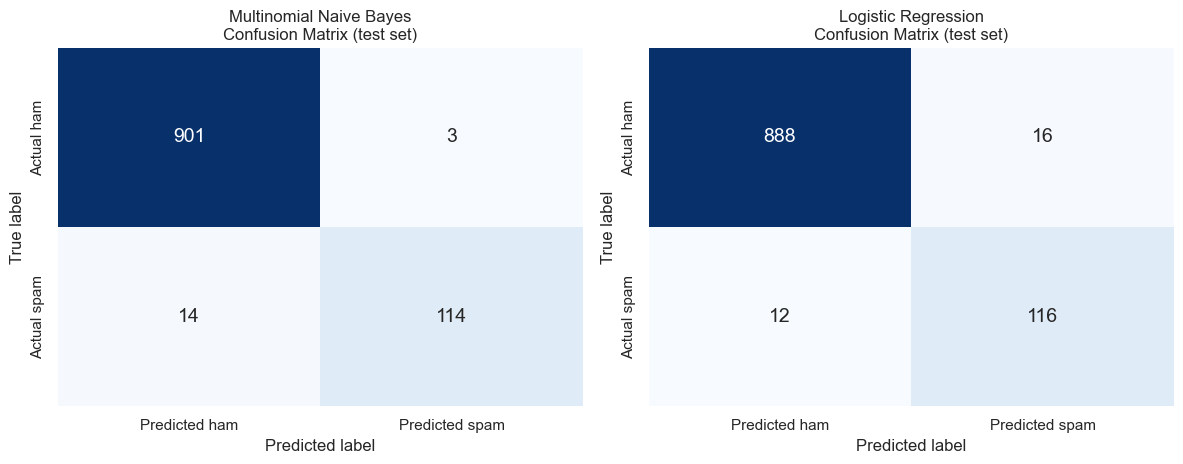

In [15]:
fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 4.8))
axes = np.atleast_1d(axes)

for ax, (name, res) in zip(axes, results.items()):
    sns.heatmap(res["cm"], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted ham", "Predicted spam"],
                yticklabels=["Actual ham", "Actual spam"], annot_kws={"size": 14})
    ax.set_title(f"{name}\nConfusion Matrix (test set)")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

### Why spam recall matters (and why precision matters too)

**Recall (for spam)** = caught spam ÷ all real spam.
A low recall means many spam messages are **incorrectly classified as legitimate** (false negatives) and reach the user's inbox. Those messages can be nuisances at best, and phishing, fraud or malware links at worst. A spam filter with poor recall is not doing its main job.

**Precision (for spam)** = real spam ÷ everything flagged as spam.
A low precision means **legitimate messages are wrongly flagged as spam** (false positives). A missed password reset, bank alert, job offer or message from a friend can be costly, and users quickly lose trust in a filter that hides real messages.

**The trade-off.** Making a model more aggressive raises recall but usually lowers precision, and vice versa. **F1-score** summarises both, but the right balance depends on the application: a personal inbox may tolerate a little spam to avoid losing important mail, while a high-security setting may accept some false alarms to catch more threats. Because the classes are imbalanced, **accuracy alone is not a reliable guide**, so the model comparison below looks at all of these metrics together.

## 9. Model Comparison and Selection

,Accuracy,Precision,Recall,F1-score,False Positives (ham->spam),False Negatives (spam->ham)
Model,,,,,,
Multinomial Naive Bayes,0.9835,0.9744,0.8906,0.9306,3.000000,14.000000
Logistic Regression,0.9729,0.8788,0.9062,0.8923,16.000000,12.000000


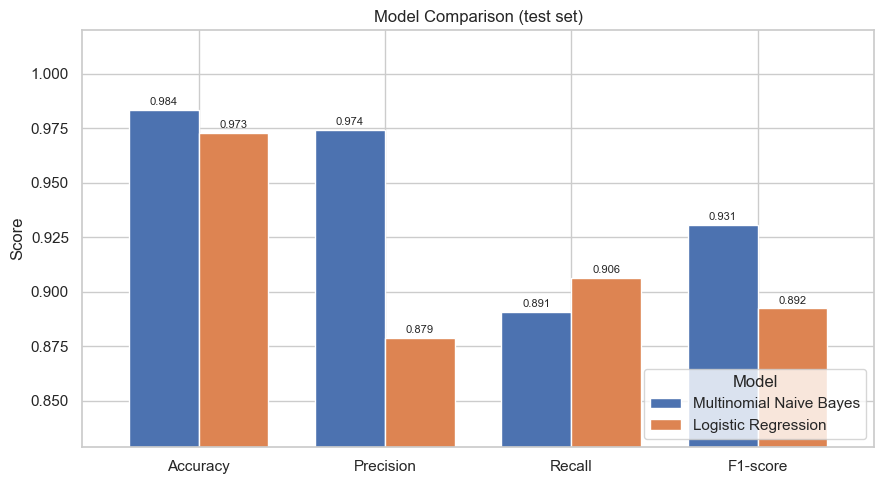

In [16]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score",
               "False Positives (ham->spam)", "False Negatives (spam->ham)"]
comparison = pd.DataFrame({name: {m: res[m] for m in metric_cols} for name, res in results.items()}).T
comparison.index.name = "Model"

float_cols = ["Accuracy", "Precision", "Recall", "F1-score"]
display(comparison.style.format({c: "{:.4f}" for c in float_cols})
                        .highlight_max(subset=float_cols, color="#c6efce")
                        .set_caption("Model comparison on the held-out test set (green = best per metric)"))

# Grouped bar chart of the four main metrics
ax = comparison[float_cols].T.plot(kind="bar", figsize=(9, 5), rot=0, width=0.75,
                                   color=["#4C72B0", "#DD8452", "#55A868"][:len(comparison)])
ax.set_title("Model Comparison (test set)")
ax.set_ylabel("Score")
ymin = max(0.0, comparison[float_cols].values.min() - 0.05)
ax.set_ylim(ymin, 1.02)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

In [17]:
# Select the best model on spam F1 (balances precision and recall); recall breaks ties, then precision.
ranked = comparison.sort_values(["F1-score", "Recall", "Precision"], ascending=False)
best_name = ranked.index[0]
best_model = models[best_name]
best = comparison.loc[best_name]

print(f"Best model by spam F1-score: {best_name}\n")
for name, row in comparison.iterrows():
    print(f"{name:26s} precision={row['Precision']:.4f}  recall={row['Recall']:.4f}  "
          f"F1={row['F1-score']:.4f}  | missed spam (FN)={int(row['False Negatives (spam->ham)'])}, "
          f"ham flagged as spam (FP)={int(row['False Positives (ham->spam)'])}")

n_test = len(y_test)
print(f"\nNote: the test set has only {n_test} messages ({int(y_test.sum())} spam). "
      "A difference of one or two messages can change the metrics noticeably, so small gaps "
      "between models should not be over-interpreted.")

Best model by spam F1-score: Multinomial Naive Bayes

Multinomial Naive Bayes    precision=0.9744  recall=0.8906  F1=0.9306  | missed spam (FN)=14, ham flagged as spam (FP)=3
Logistic Regression        precision=0.8788  recall=0.9062  F1=0.8923  | missed spam (FN)=12, ham flagged as spam (FP)=16

Note: the test set has only 1032 messages (128 spam). A difference of one or two messages can change the metrics noticeably, so small gaps between models should not be over-interpreted.


### How to read the comparison (trade-offs)
The code above picks the winner **automatically from the measured test-set results** (spam F1-score, then recall, then precision), so no conclusion is hard-coded. When reading the table, keep these points in mind:

* **Precision vs recall.** Compare the *False Negatives* column (spam that slipped through) with the *False Positives* column (legitimate messages wrongly blocked). A model with the higher F1 is the better balanced choice, but if you care more about one error type, the counts matter more than the single score.
* **Accuracy can mislead.** With imbalanced classes, two models with similar accuracy can behave very differently on spam.
* **Model characteristics.** Naive Bayes is extremely fast and simple, but its probabilities tend to be over-confident. Logistic Regression is a little heavier but gives more reliable probabilities and interpretable word weights (shown next).
* **Uncertainty.** One test split gives one estimate. Cross-validated scores (Section 7) and a larger dataset would give more confidence about which model is truly better.

### Which words drive the predictions? (Logistic Regression coefficients)
Positive coefficients push a message towards **spam**, negative ones towards **ham**. This is a useful sanity check that the model learned sensible patterns.

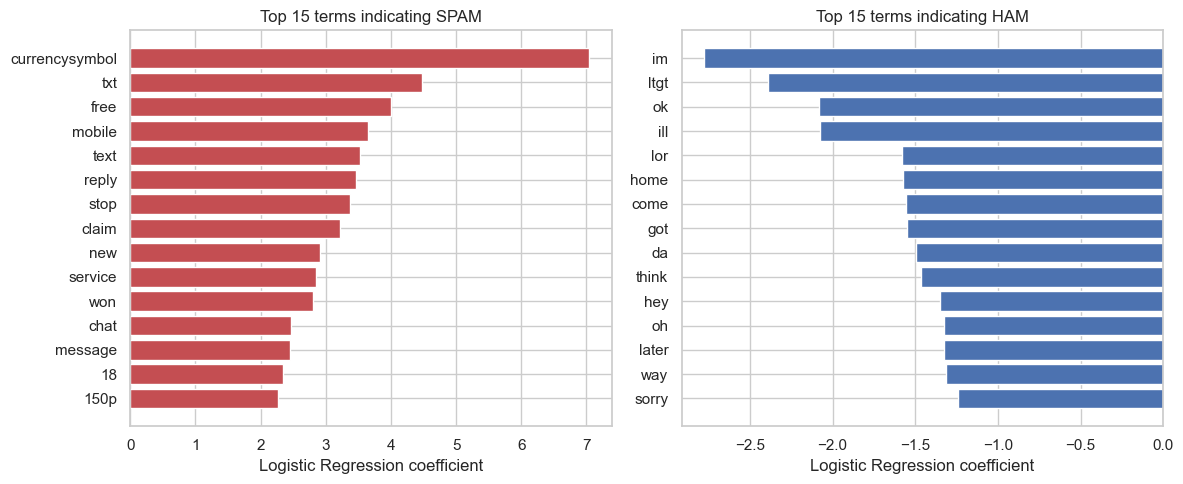

In [18]:
lr_pipe = models["Logistic Regression"]
feature_names = np.array(lr_pipe.named_steps["tfidf"].get_feature_names_out())
coefs = lr_pipe.named_steps["clf"].coef_[0]

top_n = 15
top_spam_idx = np.argsort(coefs)[-top_n:][::-1]
top_ham_idx = np.argsort(coefs)[:top_n]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(feature_names[top_spam_idx][::-1], coefs[top_spam_idx][::-1], color="#C44E52")
axes[0].set_title(f"Top {top_n} terms indicating SPAM")
axes[1].barh(feature_names[top_ham_idx][::-1], coefs[top_ham_idx][::-1], color="#4C72B0")
axes[1].set_title(f"Top {top_n} terms indicating HAM")
for ax in axes:
    ax.set_xlabel("Logistic Regression coefficient")
plt.tight_layout()
plt.show()

### Error analysis: which messages does the selected model get wrong?
Looking at actual mistakes helps to understand the model's limits.

In [19]:
best_pred = results[best_name]["y_pred"]
errors = pd.DataFrame({
    "message": df.loc[X_test.index, "message"].values,
    "actual": y_test.map({0: "ham", 1: "spam"}).values,
    "predicted": pd.Series(best_pred).map({0: "ham", 1: "spam"}).values,
})
errors = errors[errors["actual"] != errors["predicted"]]

print(f"{best_name}: {len(errors)} misclassified test messages\n")
print("Spam missed (false negatives):")
display(errors[errors["actual"] == "spam"].head(5))
print("Ham wrongly flagged (false positives):")
display(errors[errors["actual"] == "ham"].head(5))

Multinomial Naive Bayes: 17 misclassified test messages

Spam missed (false negatives):


,message,actual,predicted
77,Cashbin.co.uk (Get lots of cash this weekend!) www.cashbin.co.uk Dear Welcome to the weekend We ...,spam,ham
205,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,spam,ham
299,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Thi...",spam,ham
354,Hi I'm sue. I am 20 years old and work as a lapdancer. I love sex. Text me live - I'm i my bedro...,spam,ham
389,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a se...,spam,ham


Ham wrongly flagged (false positives):


,message,actual,predicted
105,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phon...,ham,spam
254,Nokia phone is lovly..,ham,spam
508,Have you laid your airtel line to rest?,ham,spam


## 10. Spam and Ham WordClouds (Optional Bonus)
WordClouds show the most frequent words in each class (bigger = more frequent). This is for *exploration only* and is not used to train any model. If `wordcloud` is not installed, the cell tries to install it and otherwise skips gracefully (to install manually: `pip install wordcloud`).

'wordcloud' not found. Trying to install it ...


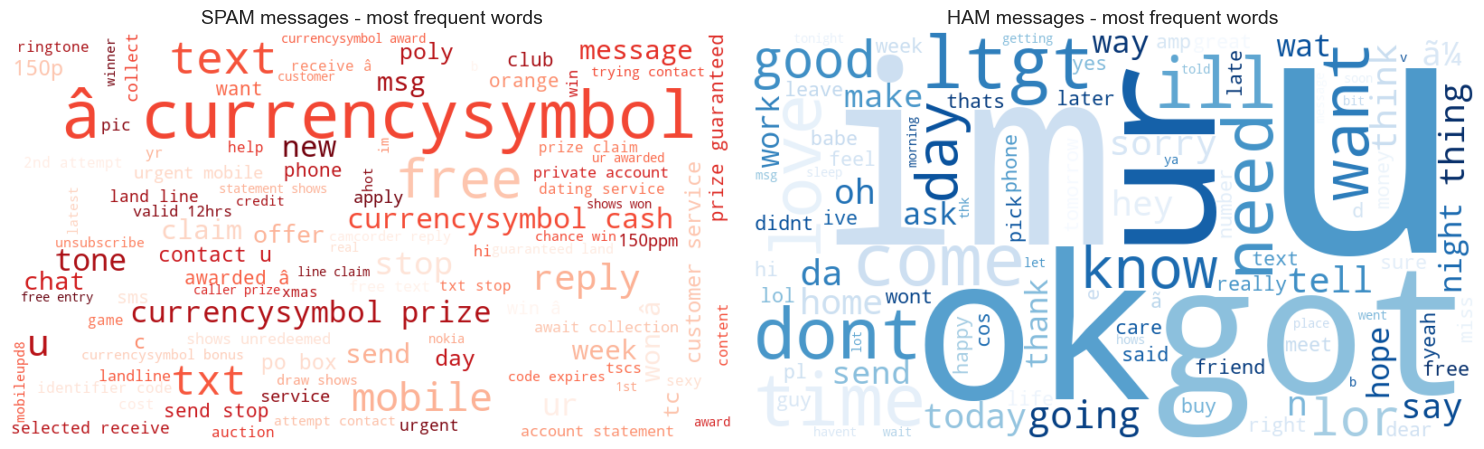

In [20]:
WORDCLOUD_AVAILABLE = False
try:
    from wordcloud import WordCloud
    WORDCLOUD_AVAILABLE = True
except ImportError:
    print("'wordcloud' not found. Trying to install it ...")
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                               "--disable-pip-version-check", "--timeout", "15", "--retries", "1", "wordcloud"])
        from wordcloud import WordCloud
        WORDCLOUD_AVAILABLE = True
    except Exception as err:
        print(f"Could not install 'wordcloud' ({type(err).__name__}). Skipping WordClouds; "
              "the rest of the notebook is unaffected.")

if WORDCLOUD_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, (cls, colormap) in zip(axes, [("spam", "Reds"), ("ham", "Blues")]):
        text = " ".join(df.loc[df["label"] == cls, "clean_message"])
        wc = WordCloud(width=800, height=450, background_color="white", colormap=colormap,
                       max_words=100, random_state=RANDOM_STATE).generate(text)
        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(f"{cls.upper()} messages - most frequent words", fontsize=14)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 11. Predictions on New Messages
New messages go through the **same `clean_text` function**, then each trained pipeline (which applies its own fitted TF-IDF) predicts the label. `predict_proba` gives the model's estimated probability of each class. Both models support it.

> The example messages below are made up for demonstration.

In [21]:
new_messages = [
    "Congratulations! You have won a $1000 gift card. Call 08001234567 now to claim your prize!",
    "Hey, are we still meeting for lunch tomorrow at 1pm?",
    "URGENT! Your account has been selected for a free holiday. Text WIN to 80086 to claim.",
    "Can you send me the notes from today's class? Thanks!",
    "FREE entry in our weekly competition! Text WIN to 87121 to receive entry question. T&Cs apply.",
    "Your OTP for the transaction is 482913. Do not share it with anyone.",
]

cleaned_new = [clean_text(m) for m in new_messages]
pred_table = pd.DataFrame({"Message": new_messages})

for name, pipe in models.items():
    labels = pipe.predict(cleaned_new)
    pred_table[f"{name}: label"] = [CLASS_NAMES[i] for i in labels]
    if hasattr(pipe, "predict_proba"):
        spam_col = list(pipe.classes_).index(1)                 # column of the spam class
        pred_table[f"{name}: P(spam)"] = pipe.predict_proba(cleaned_new)[:, spam_col].round(3)

pd.set_option("display.width", 200)
print(f"Selected model: {best_name}\n")
display(pred_table)

# Compact view for the selected model only
best_labels = best_model.predict(cleaned_new)
best_proba = best_model.predict_proba(cleaned_new)
for msg, lab, proba in zip(new_messages, best_labels, best_proba):
    print(f"[{CLASS_NAMES[lab].upper():4s}]  P(ham)={proba[0]:.3f}  P(spam)={proba[1]:.3f}  |  {msg[:70]}")

Selected model: Multinomial Naive Bayes



,Message,Multinomial Naive Bayes: label,Multinomial Naive Bayes: P(spam),Logistic Regression: label,Logistic Regression: P(spam)
0,Congratulations! You have won a $1000 gift card. Call 08001234567 now to claim your prize!,spam,1.000,spam,0.977
1,"Hey, are we still meeting for lunch tomorrow at 1pm?",ham,0.001,ham,0.057
2,URGENT! Your account has been selected for a free holiday. Text WIN to 80086 to claim.,spam,0.998,spam,0.971
3,Can you send me the notes from today's class? Thanks!,ham,0.058,ham,0.244
4,FREE entry in our weekly competition! Text WIN to 87121 to receive entry question. T&Cs apply.,spam,1.000,spam,0.933
5,Your OTP for the transaction is 482913. Do not share it with anyone.,ham,0.020,ham,0.190


[SPAM]  P(ham)=0.000  P(spam)=1.000  |  Congratulations! You have won a $1000 gift card. Call 08001234567 now 
[HAM ]  P(ham)=0.999  P(spam)=0.001  |  Hey, are we still meeting for lunch tomorrow at 1pm?
[SPAM]  P(ham)=0.002  P(spam)=0.998  |  URGENT! Your account has been selected for a free holiday. Text WIN to
[HAM ]  P(ham)=0.942  P(spam)=0.058  |  Can you send me the notes from today's class? Thanks!
[SPAM]  P(ham)=0.000  P(spam)=1.000  |  FREE entry in our weekly competition! Text WIN to 87121 to receive ent
[HAM ]  P(ham)=0.980  P(spam)=0.020  |  Your OTP for the transaction is 482913. Do not share it with anyone.


In [22]:
# Optional: save the selected pipeline so it can be reused without retraining.
# Remember to apply clean_text() to any new message before calling .predict().
import joblib
joblib.dump(best_model, "spam_classifier_pipeline.joblib")
print("Saved selected model to spam_classifier_pipeline.joblib")

Saved selected model to spam_classifier_pipeline.joblib


## 12. Conclusion and Limitations

### Conclusion
* We built a complete, leakage-aware text-classification workflow: inspect data → remove duplicates → clean text → TF-IDF inside a `Pipeline` → stratified 80/20 split → train two models → evaluate on the same held-out test set.
* Both a probabilistic model (Multinomial Naive Bayes) and a linear model (Logistic Regression) were compared using accuracy, precision, recall, F1 and confusion matrices. The **best model was selected programmatically from the measured results (spam F1, with recall as the tie-breaker)** rather than from accuracy alone. See the comparison table in Section 9 for the actual numbers from your run.
* Because spam is the minority class, recall and precision for spam describe the filter's real behaviour much better than accuracy.

### Limitations
* **Small, old dataset.** The SMS Spam Collection has only a few thousand messages, collected mostly from UK/Singapore sources. Modern spam and phishing look different, and the model may not generalise to other languages, regions or e-mail text.
* **Single split.** Test metrics come from one train/test split of a small test set, so small differences between models may be noise. Cross-validation (partially shown) or repeated splits would give a firmer comparison.
* **Bag-of-words ignores context.** TF-IDF with n-grams cannot understand meaning, sarcasm or word order beyond two-word phrases, and spammers can deliberately misspell words to evade it.
* **Limited tuning.** Hyper-parameters (`alpha`, regularisation `C`, n-gram range, `min_df`) were set to sensible defaults, not exhaustively tuned. Any tuning should use cross-validation on the training data, never the test set.
* **Preprocessing choices.** Removing punctuation discards signals such as `!!!` or all-caps; we kept digits and currency markers, but extra hand-crafted features (message length, share of capital letters, presence of URLs/phone numbers) could help.
* **Threshold choice.** Messages are classified at a 0.5 probability cut-off. In practice the threshold should be tuned to the real cost of missed spam versus blocked legitimate messages.

### Possible next steps
Hyper-parameter search with `GridSearchCV`; additional models (linear SVM, Random Forest); extra engineered features; probability calibration; and modern approaches such as word embeddings or fine-tuned transformer models.